<a href="https://colab.research.google.com/github/rolandogonzales-deeptech/Research-Methods-UNMSM-2026-II/blob/main/Gradient_Descent_Practice_Solved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical Problems on Gradient Descent Algorithms
**Complete worked solution — Problems 1–4**  
Based on the professor’s three-page handout. Run all cells in Google Colab or Jupyter. Random seed = 42 for Problems 3–4.

The cost convention for linear regression is $MSE=\frac1n\sum_i(\hat y_i-y_i)^2$; gradients include a factor of 2. SGD uses individual squared error. All reported figures are calculated, not assumed.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)
SEED=42
def mse(x,y,w,b): return float(np.mean((w*x+b-y)**2))
print("NumPy:",np.__version__)

NumPy: 2.1.3


## Problem 1 — Gradient Descent: minimum of $J(w)=(w-5)^2+4$
Derivative: $J'(w)=2(w-5)$. Update: $w_{t+1}=w_t-0.1\,2(w_t-5)$. The theoretical minimum is $w^*=5$, $J(w^*)=4$.

iteration | w | J(w)
 0 |   0.0000000 |  29.0000000
 1 |   1.0000000 |  20.0000000
 2 |   1.8000000 |  14.2400000
 3 |   2.4400000 |  10.5536000
 4 |   2.9520000 |   8.1943040
 5 |   3.3616000 |   6.6843546
 6 |   3.6892800 |   5.7179869
 7 |   3.9514240 |   5.0995116
 8 |   4.1611392 |   4.7036874
 9 |   4.3289114 |   4.4503600
10 |   4.4631291 |   4.2882304
11 |   4.5705033 |   4.1844674
12 |   4.6564026 |   4.1180592
13 |   4.7251221 |   4.0755579
14 |   4.7800977 |   4.0483570
15 |   4.8240781 |   4.0309485
16 |   4.8592625 |   4.0198070
17 |   4.8874100 |   4.0126765
18 |   4.9099280 |   4.0081130
19 |   4.9279424 |   4.0051923
20 |   4.9423539 |   4.0033231
21 |   4.9538831 |   4.0021268
22 |   4.9631065 |   4.0013611
23 |   4.9704852 |   4.0008711
24 |   4.9763882 |   4.0005575
25 |   4.9811105 |   4.0003568
26 |   4.9848884 |   4.0002284
27 |   4.9879107 |   4.0001462
28 |   4.9903286 |   4.0000935
29 |   4.9922629 |   4.0000599
30 |   4.9938103 |   4.0000383
Final w=4.99381030

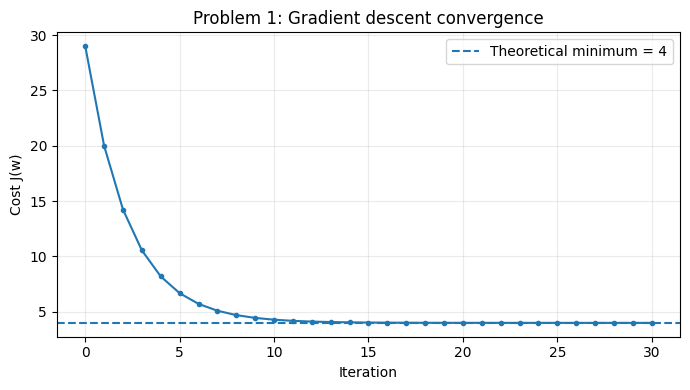

In [8]:
w=0.; alpha=0.1; history1=[]
for t in range(31):
    history1.append((t,w,(w-5)**2+4))
    if t<30: w -= alpha*2*(w-5)
print("iteration | w | J(w)")
for t,wt,j in history1: print(f"{t:2d} | {wt:11.7f} | {j:11.7f}")
print(f"Final w={w:.9f}, final cost={(w-5)**2+4:.9f}; theoretical w*=5, J*=4")
plt.figure(figsize=(7,4));plt.plot([z[0] for z in history1],[z[2] for z in history1],marker=".");plt.axhline(4,ls="--",label="Theoretical minimum = 4");plt.xlabel("Iteration");plt.ylabel("Cost J(w)");plt.title("Problem 1: Gradient descent convergence");plt.legend();plt.grid(alpha=.25);plt.tight_layout();plt.savefig("gradient_problem1.png",dpi=160);plt.show()

## Problem 2 — Batch Gradient Descent: exam scores
$\hat y=wx+b$; $\partial MSE/\partial w=\frac2n\sum x_i(\hat y_i-y_i)$ and $\partial MSE/\partial b=\frac2n\sum(\hat y_i-y_i)$. Every update uses all six examples.

w=7.430466, b=26.380290, final MSE=1.502471, predicted exam score for 7 hours=78.393551
Closed-form OLS comparison: [ 7.285714 27.      ]


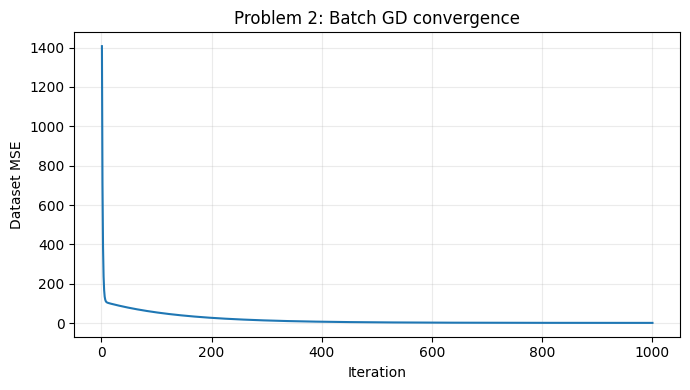

In [12]:
x2=np.array([1,2,3,4,5,6],float);y2=np.array([35,40,50,55,65,70],float)
w2=b2=0.;hist2=[]
for epoch in range(1000):
    err=w2*x2+b2-y2
    w2-=0.01*2*np.mean(x2*err)
    b2-=0.01*2*np.mean(err)
    hist2.append(mse(x2,y2,w2,b2))
print(f"w={w2:.6f}, b={b2:.6f}, final MSE={hist2[-1]:.6f}, predicted exam score for 7 hours={7*w2+b2:.6f}")
print("Closed-form OLS comparison:",np.polyfit(x2,y2,1))
plt.figure(figsize=(7,4));plt.plot(range(1,1001),hist2);plt.xlabel("Iteration");plt.ylabel("Dataset MSE");plt.title("Problem 2: Batch GD convergence");plt.grid(alpha=.25);plt.tight_layout();plt.savefig("gradient_problem2.png",dpi=160);plt.show()

## Problem 3 — Stochastic Gradient Descent: house prices
One sample per update; shuffled at the start of each of 200 epochs. For an individual sample $i$, $\nabla_w (\hat y_i-y_i)^2=2x_i(\hat y_i-y_i)$ and $\nabla_b=2(\hat y_i-y_i)$. The dataset-level MSE is evaluated after each epoch. Units: price in **₹ lakhs**; area in **100 sq. ft.**

w=3.838908, b=0.559091, final MSE=0.131470, predicted price at 1,000 sq.ft. (x=10)=38.948173 ₹ lakhs
OLS reference: [3.75 1.45]


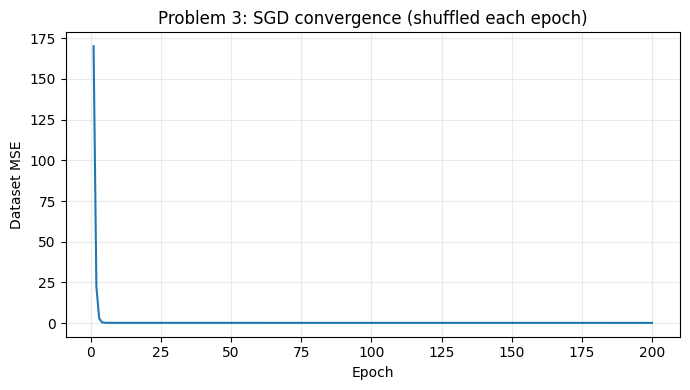

In [13]:
x3=np.array([5,7,9,11,13],float);y3=np.array([20,28,35,43,50],float)
rng=np.random.default_rng(SEED);w3=b3=0.;hist3=[]
for epoch in range(200):
    for i in rng.permutation(len(x3)):
        err=w3*x3[i]+b3-y3[i]
        w3-=0.001*2*x3[i]*err
        b3-=0.001*2*err
    hist3.append(mse(x3,y3,w3,b3))
print(f"w={w3:.6f}, b={b3:.6f}, final MSE={hist3[-1]:.6f}, predicted price at 1,000 sq.ft. (x=10)={10*w3+b3:.6f} ₹ lakhs")
print("OLS reference:",np.polyfit(x3,y3,1))
plt.figure(figsize=(7,4));plt.plot(range(1,201),hist3);plt.xlabel("Epoch");plt.ylabel("Dataset MSE");plt.title("Problem 3: SGD convergence (shuffled each epoch)");plt.grid(alpha=.25);plt.tight_layout();plt.savefig("gradient_problem3.png",dpi=160);plt.show()

## Problem 4 — Mini-Batch Gradient Descent: salaries
Use mini-batches of size 2 and 4, separately, each for 200 epochs with learning rate 0.001 and shuffling at every epoch. For each mini-batch, gradients are the **mean** of the individual squared-error gradients. Salaries are in **₹ thousands per month**. Both runs use a fresh RNG initialized to seed 42 for repeatability.

batch=2: w=8.354493, b=6.231963, MSE=30.952662, salary at 6.5 years=60.536169 ₹ thousands/month
batch=4: w=8.728245, b=4.108360, MSE=42.514019, salary at 6.5 years=60.841951 ₹ thousands/month
OLS reference: [ 6.190476 18.392857]


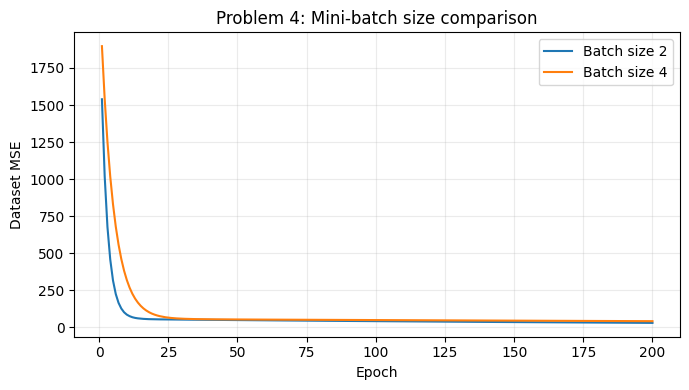

In [14]:
x4=np.array([1,2,3,4,5,6,7,8],float);y4=np.array([25,30,38,42,50,55,62,68],float)
def mini_batch_fit(batch_size,seed=SEED):
    rng=np.random.default_rng(seed);w=b=0.;history=[]
    for epoch in range(200):
        order=rng.permutation(len(x4))
        for start in range(0,len(x4),batch_size):
            idx=order[start:start+batch_size]
            err=w*x4[idx]+b-y4[idx]
            gw=2*np.mean(x4[idx]*err);gb=2*np.mean(err)
            w-=0.001*gw;b-=0.001*gb
        history.append(mse(x4,y4,w,b))
    return w,b,history
results4={}
for bs in (2,4):
    w,b,h=mini_batch_fit(bs);results4[bs]=(w,b,h)
    print(f"batch={bs}: w={w:.6f}, b={b:.6f}, MSE={h[-1]:.6f}, salary at 6.5 years={6.5*w+b:.6f} ₹ thousands/month")
print("OLS reference:",np.polyfit(x4,y4,1))
plt.figure(figsize=(7,4))
for bs,(w,b,h) in results4.items():plt.plot(range(1,201),h,label=f"Batch size {bs}")
plt.xlabel("Epoch");plt.ylabel("Dataset MSE");plt.title("Problem 4: Mini-batch size comparison");plt.legend();plt.grid(alpha=.25);plt.tight_layout();plt.savefig("gradient_problem4.png",dpi=160);plt.show()

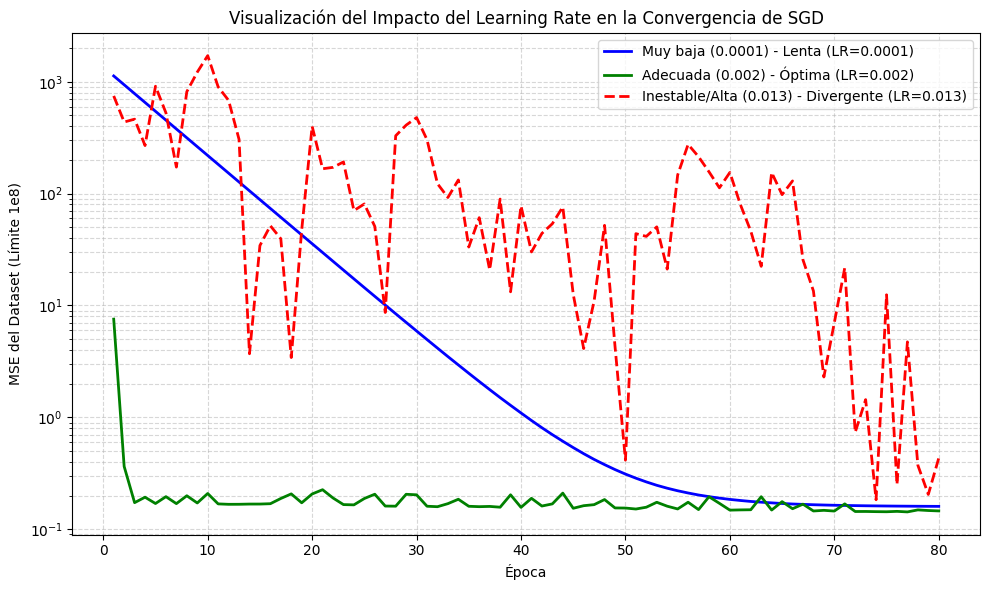

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Datos del Problema 3
x3 = np.array([5, 7, 9, 11, 13], float)
y3 = np.array([20, 28, 35, 43, 50], float)
SEED = 42

def run_sgd(learning_rate, epochs=100):
    rng = np.random.default_rng(SEED)
    w = 0.0
    b = 0.0
    history = []
    for epoch in range(epochs):
        for i in rng.permutation(len(x3)):
            err = w * x3[i] + b - y3[i]
            w -= learning_rate * 2 * x3[i] * err
            b -= learning_rate * 2 * err
        # Calculamos el MSE de manera segura para evitar fallos de visualización drásticos
        current_mse = float(np.mean((w * x3 + b - y3)**2))
        # Limitamos el valor máximo guardado para mantener el gráfico legible en escala logarítmica
        history.append(min(current_mse, 1e8))
    return history

# Ajustamos las tasas de aprendizaje para una mejor visualización del fenómeno
lrs = {
    'Muy baja (0.0001) - Lenta': (0.0001, 'blue', '-'),
    'Adecuada (0.002) - Óptima': (0.002, 'green', '-'),
    'Inestable/Alta (0.013) - Divergente': (0.013, 'red', '--')
}

plt.figure(figsize=(10, 6))

for label, (lr, color, style) in lrs.items():
    hist = run_sgd(lr, epochs=80)
    plt.plot(range(1, 81), hist, label=f"{label} (LR={lr})", color=color, linestyle=style, linewidth=2)

plt.xlabel("Época")
plt.ylabel("MSE del Dataset (Límite 1e8)")
plt.title("Visualización del Impacto del Learning Rate en la Convergencia de SGD")
plt.yscale("log")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("sgd_learning_rate_comparison.png", dpi=160)
plt.show()

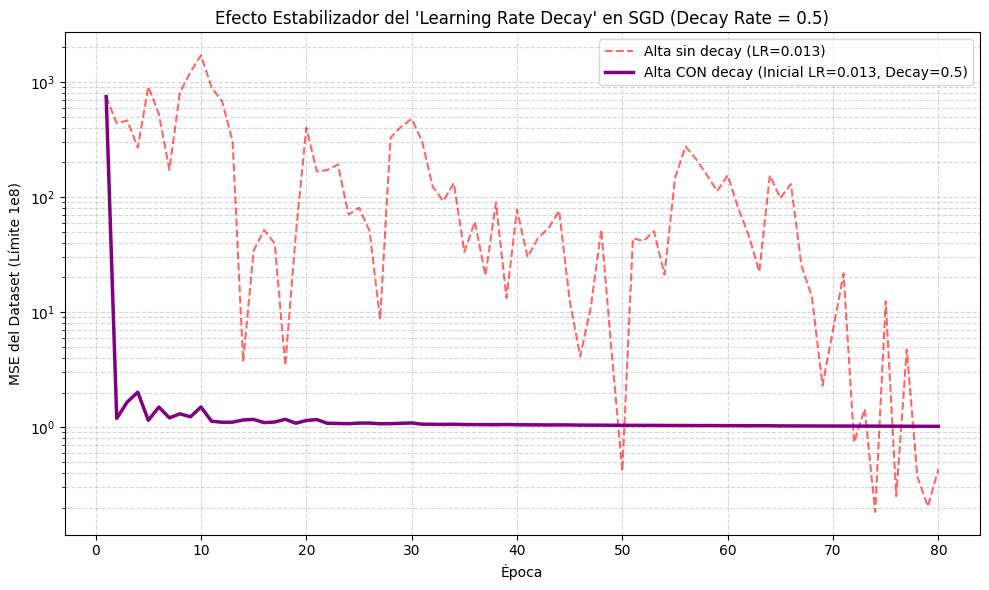

In [18]:
import numpy as np
import matplotlib.pyplot as plt

x3 = np.array([5, 7, 9, 11, 13], float)
y3 = np.array([20, 28, 35, 43, 50], float)
SEED = 42

def run_sgd_with_decay(initial_lr, decay_rate=0.05, epochs=80):
    rng = np.random.default_rng(SEED)
    w = 0.0
    b = 0.0
    history = []
    for epoch in range(epochs):
        # Aplicamos decaimiento de la tasa de aprendizaje: lr = lr_0 / (1 + decay * epoch)
        current_lr = initial_lr / (1.0 + decay_rate * epoch)
        for i in rng.permutation(len(x3)):
            err = w * x3[i] + b - y3[i]
            w -= current_lr * 2 * x3[i] * err
            b -= current_lr * 2 * err
        current_mse = float(np.mean((w * x3 + b - y3)**2))
        history.append(min(current_mse, 1e8))
    return history

# Obtener trayectorias anteriores
from __main__ import run_sgd
hist_alta = run_sgd(0.013, epochs=80)
# Modificamos decay_rate a 0.5 según lo solicitado
hist_con_decay = run_sgd_with_decay(0.013, decay_rate=0.5, epochs=80)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 81), hist_alta, label="Alta sin decay (LR=0.013)", color="red", linestyle="--", alpha=0.6)
plt.plot(range(1, 81), hist_con_decay, label="Alta CON decay (Inicial LR=0.013, Decay=0.5)", color="purple", linestyle="-", linewidth=2.5)

plt.xlabel("Época")
plt.ylabel("MSE del Dataset (Límite 1e8)")
plt.title("Efecto Estabilizador del 'Learning Rate Decay' en SGD (Decay Rate = 0.5)")
plt.yscale("log")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("sgd_learning_rate_decay_comparison.png", dpi=160)
plt.show()

## Interpretation and conclusions
- **Problem 1:** The gradient approaches zero as $w$ approaches 5; after a finite number of updates, the numerical result approximates the theoretical optimum.
- **Problem 2:** Batch GD uses the complete training set for each update; its loss curve is typically smooth for this convex quadratic objective. At 1,000 updates, parameters need not exactly equal the closed-form least-squares solution.
- **Problem 3:** SGD uses a single example per update, so the epoch-level loss may fluctuate; the fixed random seed makes the specific trajectory reproducible.
- **Problem 4:** Batch size 2 performs four updates per epoch, versus two for batch size 4. Thus a faster reduction per **epoch** does not necessarily mean greater efficiency per **gradient update** or equal computational cost.
- All predictions are illustrative extrapolations/interpolations from very small datasets and should not be treated as externally validated predictions.